In [1]:
%pip install pandas matplotlib scikit-learn nltk

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\hp\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


Dataset Columns: ['review', 'sentiment']

Total Reviews: 200

Preprocessed Reviews:
0    [one, review, mention, watch, oz, episod, youl...
1    [wonder, littl, product, br, br, film, techniq...
2    [thought, wonder, way, spend, time, hot, summe...
3    [basic, there, famili, littl, boy, jake, think...
4    [petter, mattei, love, time, money, visual, st...
Name: review, dtype: object

Top 10 Most Common Words:
br: 494
movi: 406
film: 370
one: 180
like: 169
get: 122
see: 116
even: 113
make: 108
watch: 103


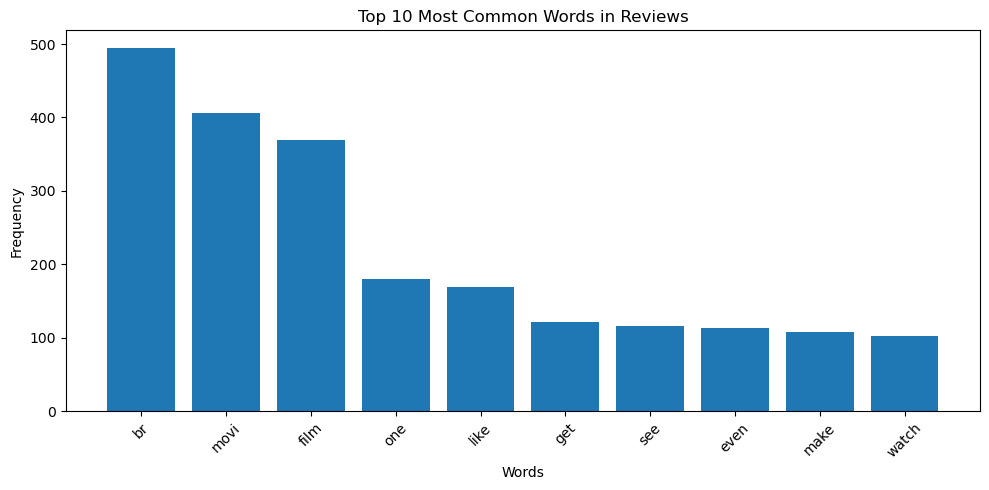


Top 10 TF-IDF Keywords:
br: 12.7404
movi: 12.6014
film: 10.6214
one: 5.6018
like: 5.4863
see: 4.6145
would: 4.4254
watch: 4.4201
make: 4.1795
even: 4.1643


In [ ]:

# NLP Practical: Review Analysis Using Text Preprocessing and TF-IDF

# 1. Import libraries
import pandas as pd
import matplotlib.pyplot as plt
import re
import nltk

from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from collections import Counter
from sklearn.feature_extraction.text import TfidfVectorizer

# 2. Download stopwords
nltk.download('stopwords')

# 3. Load Kaggle CSV dataset
df = pd.read_csv("reviews.csv")

# Display column names
print("Dataset Columns:", df.columns.tolist())

# 4. Select the review column
# Change 'review' to your actual column name if necessary
review_column = 'review'

# Select up to 200 reviews
reviews = df[review_column].dropna().astype(str).head(200)

print("\nTotal Reviews:", len(reviews))

# 5. Initialize stopwords and stemmer
stop_words = set(stopwords.words('english'))
stemmer = PorterStemmer()

# 6. Text preprocessing function
def preprocess(text):
    text = text.lower()
    text = re.sub(r'[^a-z\s]', '', text)
    words = text.split()
    words = [word for word in words if word not in stop_words]
    words = [stemmer.stem(word) for word in words]
    return words

# 7. Preprocess reviews
processed_reviews = reviews.apply(preprocess)

print("\nPreprocessed Reviews:")
print(processed_reviews.head())

# 8. Find the 10 most common words
all_words = [
    word
    for review in processed_reviews
    for word in review
]

word_counts = Counter(all_words)
top_words = word_counts.most_common(10)

print("\nTop 10 Most Common Words:")
for word, count in top_words:
    print(f"{word}: {count}")

# 9. Plot bar chart
if top_words:
    words = [word for word, count in top_words]
    counts = [count for word, count in top_words]

    plt.figure(figsize=(10, 5))
    plt.bar(words, counts)
    plt.xlabel("Words")
    plt.ylabel("Frequency")
    plt.title("Top 10 Most Common Words in Reviews")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
else:
    print("No words available to plot.")

# 10. Calculate TF-IDF
processed_texts = [
    ' '.join(words)
    for words in processed_reviews
]

# Remove empty reviews
processed_texts = [
    text for text in processed_texts if text.strip()
]

if processed_texts:
    vectorizer = TfidfVectorizer()
    tfidf_matrix = vectorizer.fit_transform(processed_texts)

    # Sum TF-IDF scores across all reviews
    scores = tfidf_matrix.sum(axis=0).A1
    keywords = vectorizer.get_feature_names_out()

    # Get top 10 keywords
    top_indices = scores.argsort()[-10:][::-1]

    print("\nTop 10 TF-IDF Keywords:")
    for index in top_indices:
        print(f"{keywords[index]}: {scores[index]:.4f}")
else:
    print("No text available for TF-IDF analysis.")